# Évaluation du modèle RoBERTa fine-tuné pour la NER

Ce notebook permet de :
- Charger et tester le modèle fine-tuné
- Évaluer les performances sur le dataset de test
- Visualiser les résultats avec des graphiques
- Comparer avec les résultats attendus

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForTokenClassification, pipeline
import torch
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
import json
import re
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## 1. Chargement du modèle

In [3]:
# Chemin du modèle fine-tuné
model_path = "./roberta_ner_model"

# Charge le tokenizer et le modèle
print(f"Chargement du modèle depuis {model_path}...")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForTokenClassification.from_pretrained(model_path)

# Crée le pipeline NER
ner_pipeline = pipeline(
    "ner",
    model=model,
    tokenizer=tokenizer,
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1
)

# Charge le mapping des labels
with open(f"{model_path}/label_mapping.json", "r") as f:
    label_to_id = json.load(f)
    id_to_label = {v: k for k, v in label_to_id.items()}

print(f"✅ Modèle chargé avec {len(label_to_id)} labels: {list(label_to_id.keys())}")

Device set to use cpu


Chargement du modèle depuis ./roberta_ner_model...
✅ Modèle chargé avec 3 labels: ['O', 'B-LOC', 'I-LOC']


## 2. Fonctions utilitaires

In [4]:
def extract_locations(entities):
    """Extrait les entités LOC depuis les résultats de la NER"""
    locations = []
    for entity in entities:
        label = entity.get('entity_group', entity.get('label', ''))
        label_upper = label.upper()
        if 'LOC' in label_upper or 'LOCATION' in label_upper or label_upper in ['B-LOC', 'I-LOC']:
            word = entity.get('word', entity.get('text', ''))
            word = word.strip()
            if word:
                locations.append(word)
    return locations

def predict_trajectory(phrase, ner_pipeline):
    """Prédit le départ et l'arrivée depuis une phrase"""
    entities = ner_pipeline(phrase)
    lieux = extract_locations(entities)
    
    departure = lieux[0] if len(lieux) > 0 else 'INVALID'
    arrival = lieux[-1] if len(lieux) > 1 else 'INVALID'
    
    return departure, arrival, lieux, entities

def read_dataset_input(filepath):
    """Lit le fichier d'entrée du dataset"""
    texts = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if ',' in line:
                parts = line.split(',', 1)
                if len(parts) == 2 and parts[0].strip().isdigit():
                    texts.append(parts[1].strip())
                else:
                    texts.append(line)
            else:
                texts.append(line)
    return texts

def read_dataset_output(filepath):
    """Lit le fichier de sortie attendu du dataset"""
    results = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if ',' in line:
                parts = line.split(',')
                if len(parts) >= 3:
                    idx = parts[0]
                    depart = parts[1] if parts[1] else 'INVALID'
                    arrivee = parts[2] if len(parts) > 2 and parts[2] else 'INVALID'
                    results.append((depart, arrivee))
    return results

## 3. Tests sur des exemples spécifiques

In [5]:
# Exemples de test
test_examples = [
    "je veux aller de paris à lyon",
    "je veu aller voir albert et boire un monaco",
    "trains de marseille vers toulouse",
    "je cherche un restaurant",
    "Comment aller de nantes à rennes?",
    "avec mon ami albert je voudrais aller de paris à lyon",
    "aller de albert à paris boire un monaco"
]

print("🔍 Tests sur des exemples spécifiques:\n")
for i, phrase in enumerate(test_examples, 1):
    departure, arrival, lieux, entities = predict_trajectory(phrase, ner_pipeline)
    print(f"{i}. Phrase: {phrase}")
    print(f"   Entités détectées: {[e.get('word', '') for e in entities]}")
    print(f"   Labels: {[e.get('entity_group', e.get('label', '')) for e in entities]}")
    print(f"   Lieux extraits: {lieux}")
    print(f"   → Départ: {departure}, Arrivée: {arrival}")
    print()

🔍 Tests sur des exemples spécifiques:

1. Phrase: je veux aller de paris à lyon
   Entités détectées: [' paris', ' lyon']
   Labels: ['LOC', 'LOC']
   Lieux extraits: ['paris', 'lyon']
   → Départ: paris, Arrivée: lyon

2. Phrase: je veu aller voir albert et boire un monaco
   Entités détectées: [' albert', ' monaco']
   Labels: ['LOC', 'LOC']
   Lieux extraits: ['albert', 'monaco']
   → Départ: albert, Arrivée: monaco

3. Phrase: trains de marseille vers toulouse
   Entités détectées: [' marseille', ' toulouse']
   Labels: ['LOC', 'LOC']
   Lieux extraits: ['marseille', 'toulouse']
   → Départ: marseille, Arrivée: toulouse

4. Phrase: je cherche un restaurant
   Entités détectées: []
   Labels: []
   Lieux extraits: []
   → Départ: INVALID, Arrivée: INVALID

5. Phrase: Comment aller de nantes à rennes?
   Entités détectées: [' nantes', ' rennes']
   Labels: ['LOC', 'LOC']
   Lieux extraits: ['nantes', 'rennes']
   → Départ: nantes, Arrivée: rennes

6. Phrase: avec mon ami albert je vo

## 4. Évaluation sur le dataset complet

In [6]:
# Charge les datasets
print("📊 Chargement des datasets...")
input_texts = read_dataset_input("./dataset/dataset_input.txt")
expected_outputs = read_dataset_output("./dataset/dataset_output.txt")

print(f"   - {len(input_texts)} phrases d'entrée")
print(f"   - {len(expected_outputs)} résultats attendus")

# Limite pour les tests (optionnel - enlever pour évaluer tout)
MAX_SAMPLES = None  # Mettre None pour tout évaluer, ou un nombre pour limiter
if MAX_SAMPLES:
    input_texts = input_texts[:MAX_SAMPLES]
    expected_outputs = expected_outputs[:MAX_SAMPLES]
    print(f"   ⚠️  Limité à {MAX_SAMPLES} échantillons pour les tests")

# Prédictions
print("\n🔄 Génération des prédictions...")
predictions = []
for i, phrase in enumerate(input_texts):
    if (i + 1) % 1000 == 0:
        print(f"   Traité {i + 1}/{len(input_texts)} phrases...")
    departure, arrival, _, _ = predict_trajectory(phrase, ner_pipeline)
    predictions.append((departure, arrival))

print(f"✅ {len(predictions)} prédictions générées")

📊 Chargement des datasets...
   - 11000 phrases d'entrée
   - 11000 résultats attendus

🔄 Génération des prédictions...
   Traité 1000/11000 phrases...
   Traité 2000/11000 phrases...
   Traité 3000/11000 phrases...
   Traité 4000/11000 phrases...
   Traité 5000/11000 phrases...
   Traité 6000/11000 phrases...
   Traité 7000/11000 phrases...
   Traité 8000/11000 phrases...
   Traité 9000/11000 phrases...
   Traité 10000/11000 phrases...
   Traité 11000/11000 phrases...
✅ 11000 prédictions générées


## 5. Calcul des métriques

In [7]:
# Compare les prédictions avec les résultats attendus
correct_depart = 0
correct_arrival = 0
correct_both = 0
total = len(predictions)

results_df = []
for i, ((pred_dep, pred_arr), (exp_dep, exp_arr)) in enumerate(zip(predictions, expected_outputs)):
    dep_correct = (pred_dep.lower() == exp_dep.lower() if exp_dep != 'INVALID' else pred_dep == exp_dep)
    arr_correct = (pred_arr.lower() == exp_arr.lower() if exp_arr != 'INVALID' else pred_arr == exp_arr)
    
    if dep_correct:
        correct_depart += 1
    if arr_correct:
        correct_arrival += 1
    if dep_correct and arr_correct:
        correct_both += 1
    
    results_df.append({
        'phrase': input_texts[i][:50] + '...' if len(input_texts[i]) > 50 else input_texts[i],
        'expected_depart': exp_dep,
        'predicted_depart': pred_dep,
        'expected_arrival': exp_arr,
        'predicted_arrival': pred_arr,
        'depart_correct': dep_correct,
        'arrival_correct': arr_correct,
        'both_correct': dep_correct and arr_correct
    })

df_results = pd.DataFrame(results_df)

# Métriques globales
accuracy_depart = correct_depart / total
accuracy_arrival = correct_arrival / total
accuracy_both = correct_both / total

print("📈 Métriques globales:\n")
print(f"   Précision sur le départ:     {accuracy_depart:.2%} ({correct_depart}/{total})")
print(f"   Précision sur l'arrivée:      {accuracy_arrival:.2%} ({correct_arrival}/{total})")
print(f"   Précision complète (les deux): {accuracy_both:.2%} ({correct_both}/{total})")

📈 Métriques globales:

   Précision sur le départ:     56.47% (6212/11000)
   Précision sur l'arrivée:      62.55% (6880/11000)
   Précision complète (les deux): 51.78% (5696/11000)


## 6. Analyse des erreurs

In [8]:
# Analyse des cas d'erreur
errors = df_results[~df_results['both_correct']].copy()

print(f"\n❌ {len(errors)} erreurs sur {total} exemples ({len(errors)/total:.2%})")
print("\n📋 Exemples d'erreurs:\n")

# Affiche les 20 premières erreurs
for idx, row in errors.head(20).iterrows():
    print(f"Phrase: {row['phrase']}")
    print(f"  Attendu:  {row['expected_depart']} → {row['expected_arrival']}")
    print(f"  Prédit:   {row['predicted_depart']} → {row['predicted_arrival']}")
    print()

# Analyse des types d'erreurs
invalid_expected = df_results[df_results['expected_depart'] == 'INVALID']
invalid_predicted = df_results[df_results['predicted_depart'] == 'INVALID']

print(f"\n📊 Analyse des INVALID:")
print(f"   - Phrases attendues INVALID: {len(invalid_expected)}")
print(f"   - Phrases prédites INVALID:   {len(invalid_predicted)}")
print(f"   - INVALID correctement détectés: {len(invalid_expected[invalid_expected['predicted_depart'] == 'INVALID'])}")
print(f"   - Faux positifs (prédit INVALID mais valide): {len(df_results[(df_results['predicted_depart'] == 'INVALID') & (df_results['expected_depart'] != 'INVALID')])}")
print(f"   - Faux négatifs (prédit valide mais INVALID attendu): {len(df_results[(df_results['predicted_depart'] != 'INVALID') & (df_results['expected_depart'] == 'INVALID')])}")


❌ 5304 erreurs sur 11000 exemples (48.22%)

📋 Exemples d'erreurs:

Phrase: trains de valerie vers colombes
  Attendu:  INVALID → INVALID
  Prédit:   valerie → colombes

Phrase: je veux aller voir mon ami a amiens en partant de ...
  Attendu:  Mérignac → Amiens
  Prédit:   mon ami → merignac

Phrase: pour aller à angers depuis rouen, quels sont les t...
  Attendu:  Rouen → Angers
  Prédit:   angers → rouen

Phrase: je veux aller voir mon ami a asnieres-sur-seine en...
  Attendu:  Montreuil → Asnières-sur-Seine
  Prédit:   mon ami → montreuil

Phrase: un billet pour toulon depuis nancy
  Attendu:  Nancy → Toulon
  Prédit:   toulon → nancy

Phrase: je voudrais réserver une chambre d'hôtel
  Attendu:  INVALID → INVALID
  Prédit:   chambre → INVALID

Phrase: Trains de aulnay sous bois vers avignon
  Attendu:  Aulnay-sous-Bois → Avignon
  Prédit:   aulnay sous bois → avignon

Phrase: Je souhaite me rendre a angers depuis bordeaux
  Attendu:  Bordeaux → Angers
  Prédit:   angers → bordeaux



## 7. Visualisations

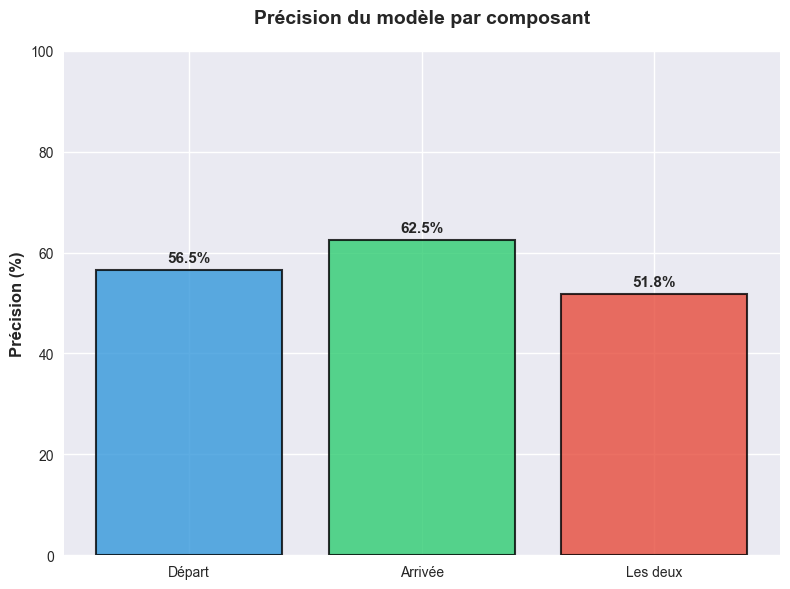

In [9]:
# Graphique 1: Métriques globales
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
metrics = ['Départ', 'Arrivée', 'Les deux']
scores = [accuracy_depart * 100, accuracy_arrival * 100, accuracy_both * 100]
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax.bar(metrics, scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Précision (%)', fontsize=12, fontweight='bold')
ax.set_title('Précision du modèle par composant', fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 100)

# Ajoute les valeurs sur les barres
for bar, score in zip(bars, scores):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{score:.1f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

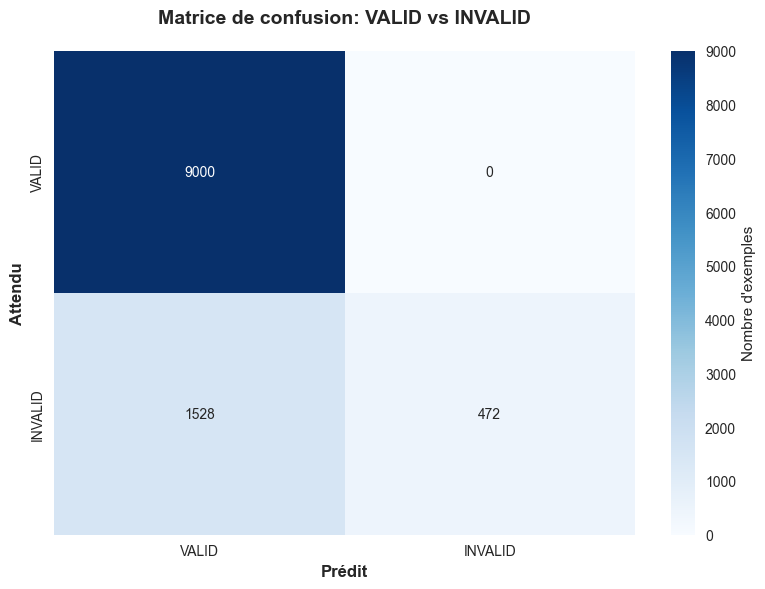

In [10]:
# Graphique 2: Matrice de confusion pour INVALID vs VALID
from sklearn.metrics import confusion_matrix

# Prépare les données pour la matrice de confusion
y_true = ['INVALID' if dep == 'INVALID' else 'VALID' for dep, _ in expected_outputs]
y_pred = ['INVALID' if dep == 'INVALID' else 'VALID' for dep, _ in predictions]

cm = confusion_matrix(y_true, y_pred, labels=['VALID', 'INVALID'])

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['VALID', 'INVALID'],
            yticklabels=['VALID', 'INVALID'],
            cbar_kws={'label': 'Nombre d\'exemples'})
ax.set_xlabel('Prédit', fontsize=12, fontweight='bold')
ax.set_ylabel('Attendu', fontsize=12, fontweight='bold')
ax.set_title('Matrice de confusion: VALID vs INVALID', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

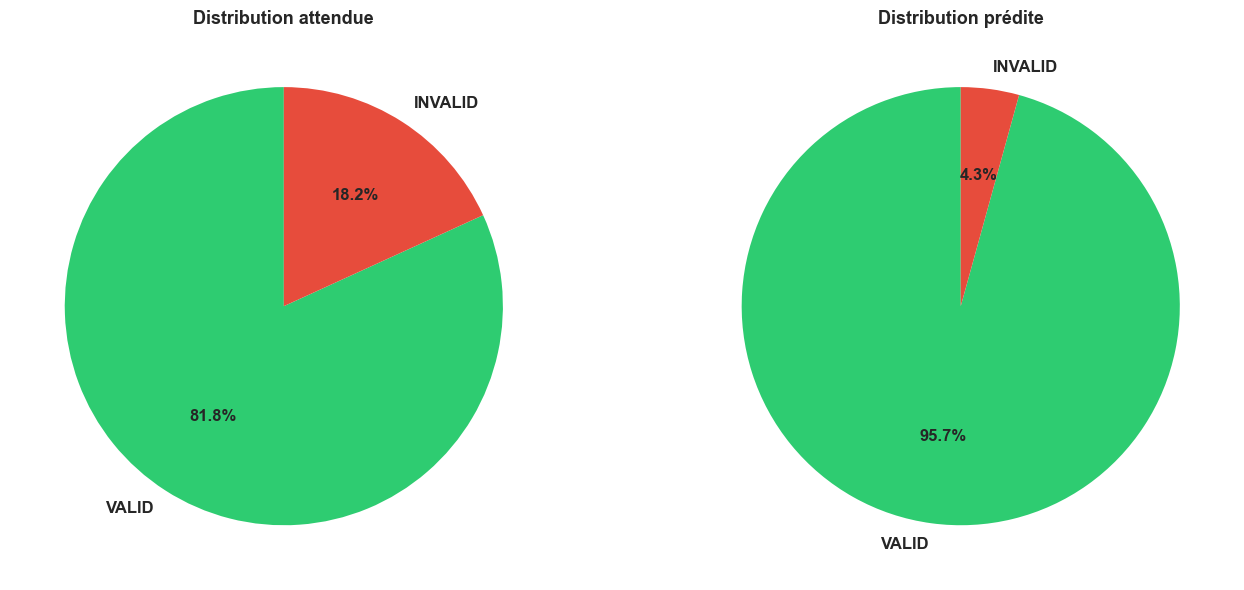

In [11]:
# Graphique 3: Distribution des types de résultats
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Distribution attendue
expected_types = Counter([dep for dep, _ in expected_outputs])
expected_valid = sum(1 for dep, _ in expected_outputs if dep != 'INVALID')
expected_invalid = sum(1 for dep, _ in expected_outputs if dep == 'INVALID')

axes[0].pie([expected_valid, expected_invalid], 
            labels=['VALID', 'INVALID'], 
            autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'],
            startangle=90,
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Distribution attendue', fontsize=13, fontweight='bold')

# Distribution prédite
predicted_valid = sum(1 for dep, _ in predictions if dep != 'INVALID')
predicted_invalid = sum(1 for dep, _ in predictions if dep == 'INVALID')

axes[1].pie([predicted_valid, predicted_invalid], 
            labels=['VALID', 'INVALID'], 
            autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'],
            startangle=90,
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Distribution prédite', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

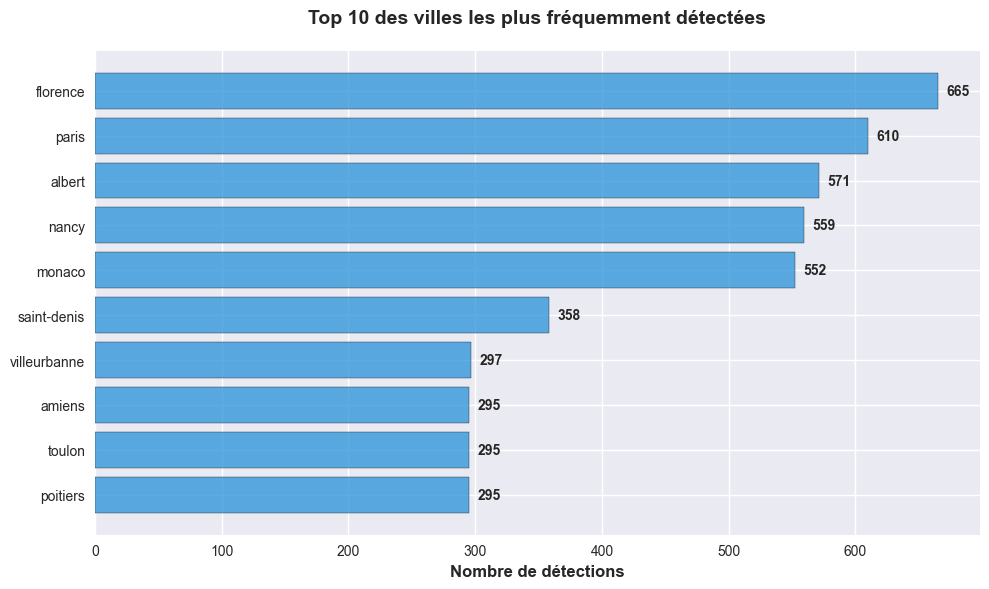

In [12]:
# Graphique 4: Top 10 des villes les plus fréquemment détectées
all_predicted_locations = []
for dep, arr in predictions:
    if dep != 'INVALID':
        all_predicted_locations.append(dep)
    if arr != 'INVALID':
        all_predicted_locations.append(arr)

location_counts = Counter(all_predicted_locations)
top_locations = location_counts.most_common(10)

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
locations, counts = zip(*top_locations)
bars = ax.barh(range(len(locations)), counts, color='#3498db', alpha=0.8, edgecolor='black')
ax.set_yticks(range(len(locations)))
ax.set_yticklabels(locations, fontsize=10)
ax.set_xlabel('Nombre de détections', fontsize=12, fontweight='bold')
ax.set_title('Top 10 des villes les plus fréquemment détectées', fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()

# Ajoute les valeurs
for i, (bar, count) in enumerate(zip(bars, counts)):
    ax.text(count + max(counts) * 0.01, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Rapport détaillé

In [13]:
# Génère un rapport détaillé
print("=" * 80)
print("📊 RAPPORT D'ÉVALUATION DU MODÈLE ROBERTA NER")
print("=" * 80)
print()
print(f"📈 MÉTRIQUES GLOBALES")
print(f"   {'-' * 50}")
print(f"   Précision sur le départ:     {accuracy_depart:.2%}")
print(f"   Précision sur l'arrivée:      {accuracy_arrival:.2%}")
print(f"   Précision complète:           {accuracy_both:.2%}")
print()
print(f"📊 ANALYSE DES ERREURS")
print(f"   {'-' * 50}")
print(f"   Total d'erreurs:              {len(errors)} ({len(errors)/total:.2%})")
print(f"   Faux positifs (INVALID):      {len(df_results[(df_results['predicted_depart'] == 'INVALID') & (df_results['expected_depart'] != 'INVALID')])}")
print(f"   Faux négatifs (VALID):        {len(df_results[(df_results['predicted_depart'] != 'INVALID') & (df_results['expected_depart'] == 'INVALID')])}")
print()
print(f"🏙️  STATISTIQUES DES VILLES")
print(f"   {'-' * 50}")
print(f"   Villes uniques détectées:     {len(set(all_predicted_locations))}")
print(f"   Total de détections:          {len(all_predicted_locations)}")
print(f"   Top 3 villes:                 {', '.join([loc for loc, _ in top_locations[:3]])}")
print()
print("=" * 80)

📊 RAPPORT D'ÉVALUATION DU MODÈLE ROBERTA NER

📈 MÉTRIQUES GLOBALES
   --------------------------------------------------
   Précision sur le départ:     56.47%
   Précision sur l'arrivée:      62.55%
   Précision complète:           51.78%

📊 ANALYSE DES ERREURS
   --------------------------------------------------
   Total d'erreurs:              5304 (48.22%)
   Faux positifs (INVALID):      0
   Faux négatifs (VALID):        1528

🏙️  STATISTIQUES DES VILLES
   --------------------------------------------------
   Villes uniques détectées:     392
   Total de détections:          20599
   Top 3 villes:                 florence, paris, albert



## 9. Export des résultats

In [ ]:
# Affiche un aperçu
print("\n📋 Aperçu des résultats:")
print(df_results.head(10).to_string())

✅ Résultats détaillés sauvegardés dans evaluation_results.csv

📋 Aperçu des résultats:
                                                  phrase expected_depart predicted_depart  expected_arrival predicted_arrival  depart_correct  arrival_correct  both_correct
0                               je cherche un restaurant         INVALID          INVALID           INVALID           INVALID            True             True          True
1          y a-t-il des trains de limoges à villeurbanne         Limoges          limoges      Villeurbanne      villeurbanne            True             True          True
2  Un voyage de amiens a vitry-sur-seine s'il vous pl...          Amiens           amiens   Vitry-sur-Seine   vitry-sur-seine            True             True          True
3             je voudrai aller de orléans à villeurbanne         Orléans          orléans      Villeurbanne      villeurbanne            True             True          True
4                              de grenoble vers 